训练发动机: [ 2  5 10 16 18]
验证发动机: 20
训练窗口数: 4,495,042
验证窗口数: 768,111
测试窗口数: 1,253,596
使用设备: cuda
训练批次数: 4,389
验证批次数: 751
模型参数量: 109,121

开始训练...
  Epoch 1, Batch 100/4389, Loss: 369.0161
  Epoch 1, Batch 200/4389, Loss: 222.2876
  Epoch 1, Batch 300/4389, Loss: 190.1389
  Epoch 1, Batch 400/4389, Loss: 242.6568
  Epoch 1, Batch 500/4389, Loss: 257.6194
  Epoch 1, Batch 600/4389, Loss: 195.2216
  Epoch 1, Batch 700/4389, Loss: 120.6463
  Epoch 1, Batch 800/4389, Loss: 131.0572
  Epoch 1, Batch 900/4389, Loss: 162.9504
  Epoch 1, Batch 1000/4389, Loss: 105.4262
  Epoch 1, Batch 1100/4389, Loss: 111.9603
  Epoch 1, Batch 1200/4389, Loss: 140.7621
  Epoch 1, Batch 1300/4389, Loss: 103.5824
  Epoch 1, Batch 1400/4389, Loss: 119.3841
  Epoch 1, Batch 1500/4389, Loss: 112.2746
  Epoch 1, Batch 1600/4389, Loss: 131.1739
  Epoch 1, Batch 1700/4389, Loss: 119.3521
  Epoch 1, Batch 1800/4389, Loss: 116.4194
  Epoch 1, Batch 1900/4389, Loss: 124.1423
  Epoch 1, Batch 2000/4389, Loss: 106.6281
  Epoch

Testing: 100%|██████████████████████████████████████████████████| 1225/1225 [01:01<00:00, 19.76it/s]



✅ 测试集 RMSE: 5.3774


C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2500059104.py:415: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2500059104.py:415: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2500059104.py:415: UserWarning: Glyph 36807 (\N{CJK UNIFIED IDEOGRAPH-8FC7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2500059104.py:415: UserWarning: Glyph 31243 (\N{CJK UNIFIED IDEOGRAPH-7A0B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2500059104.py:415: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2500059104.py:415: UserWarning: Glyph 22

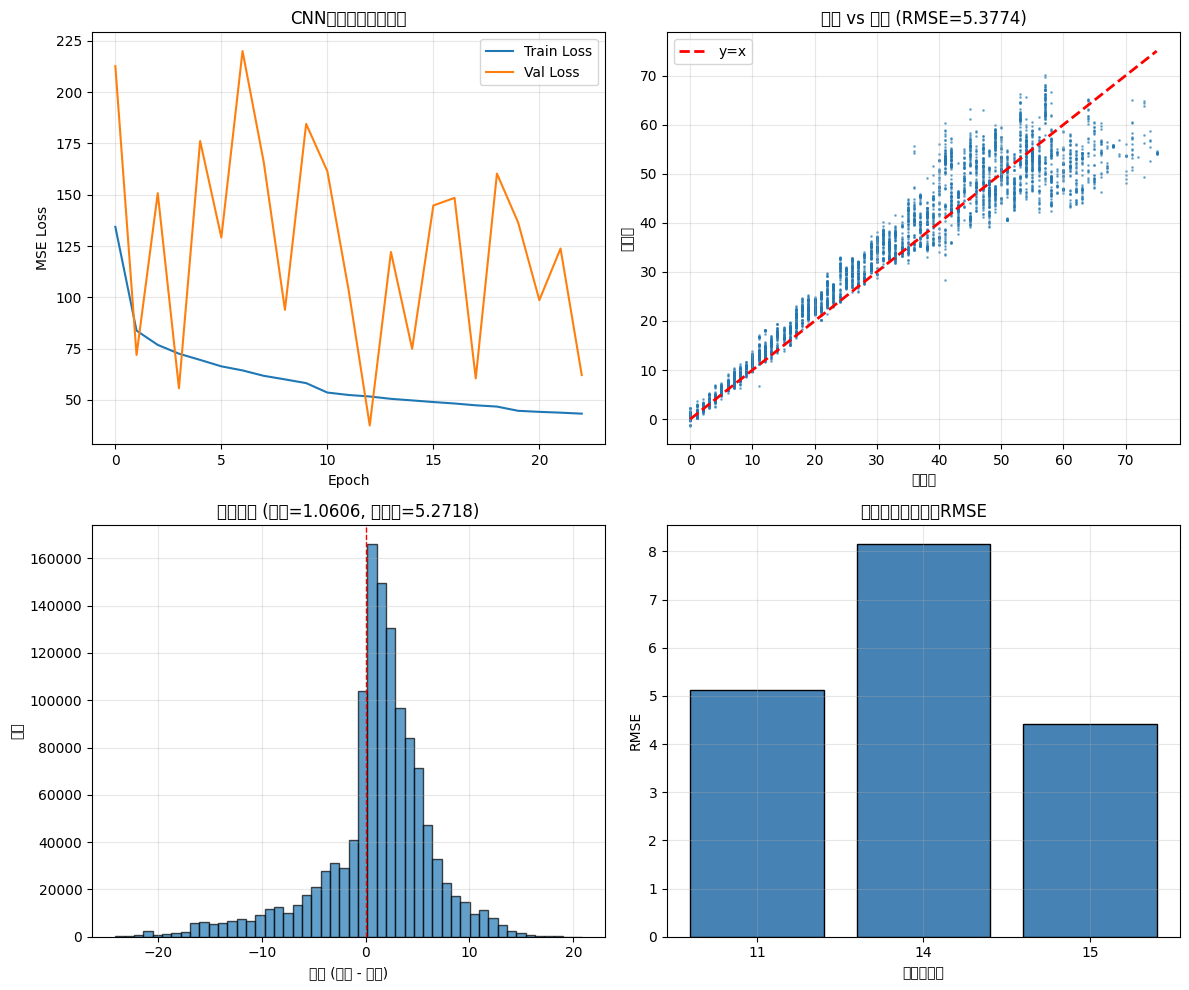


按发动机单元分别评估:


ValueError: Unknown format code 'd' for object of type 'str'

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import random
import h5py
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import time

def set_seed(seed=42):
    """固定所有随机数"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# ==================== 1. 数据加载与预处理 ====================
file_path = "N-CMAPSS_DS02-006.h5"

with h5py.File(file_path, 'r') as f:
    W_dev = f['W_dev'][:]
    Xs_dev = f['X_s_dev'][:]
    A_dev = f['A_dev'][:]
    Y_dev = f['Y_dev'][:]
    X_s_var = f['X_s_var'][:]
    W_var = f['W_var'][:]
    W_test = f['W_test'][:]
    Xs_test = f['X_s_test'][:]
    A_test = f['A_test'][:]
    Y_test = f['Y_test'][:]

# 合并工况和传感器数据
X_dev = np.concatenate([W_dev, Xs_dev], axis=1)
X_test = np.concatenate([W_test, Xs_test], axis=1)

# 记录发动机序号
unit_dev = A_dev[:, 0].astype(int)
unit_test = A_test[:, 0].astype(int)

# Min-max归一化，只使用训练集防止数据泄露
X_min = X_dev.min(axis=0)
X_max = X_dev.max(axis=0)
denom = X_max - X_min + 1e-8

X_dev = 2 * (X_dev - X_min) / denom - 1
X_test = 2 * (X_test - X_min) / denom - 1

# ==================== 2. Dataset定义 ====================
class NCMAPSSDataset(Dataset):
    def __init__(self, X, Y, unit_array, window_size=50):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32).view(-1, 1)
        self.unit = unit_array
        self.window_size = window_size

        self.valid_indices = []
        unique_units = np.unique(self.unit)

        for u in unique_units:
            indices = np.where(self.unit == u)[0]
            for i in range(len(indices) - window_size + 1):
                self.valid_indices.append(indices[i])

        self.valid_indices = np.array(self.valid_indices)

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        start = self.valid_indices[idx]
        X_window = self.X[start:start + self.window_size]
        Y_target = self.Y[start + self.window_size - 1]
        return X_window, Y_target

# ==================== 3. 按发动机划分训练集和验证集 ====================
window_size = 50
unique_dev_units = np.unique(unit_dev)

# 将最后一台发动机作为验证集
val_unit = unique_dev_units[-1]  # Unit 20
train_units = unique_dev_units[:-1]  # Unit 2, 5, 10, 16, 18

train_mask = np.isin(unit_dev, train_units)
val_mask = unit_dev == val_unit

print(f"训练发动机: {train_units}")
print(f"验证发动机: {val_unit}")

# 分别构建训练集和验证集
train_dataset = NCMAPSSDataset(
    X_dev[train_mask],
    Y_dev[train_mask],
    unit_dev[train_mask],
    window_size=window_size
)

val_dataset = NCMAPSSDataset(
    X_dev[val_mask],
    Y_dev[val_mask],
    unit_dev[val_mask],
    window_size=window_size
)

test_dataset = NCMAPSSDataset(
    X_test,
    Y_test,
    unit_test,
    window_size=window_size
)

print(f"训练窗口数: {len(train_dataset):,}")
print(f"验证窗口数: {len(val_dataset):,}")
print(f"测试窗口数: {len(test_dataset):,}")

# ==================== 4. CNN模型 ====================
class CNNModel(nn.Module):
    def __init__(self, input_size=18, window_size=50):
        super(CNNModel, self).__init__()
        
        # 输入: (batch, window_size, input_size)
        # 转换为 (batch, 1, window_size, input_size) 适配Conv2d
        
        # 第一个卷积块: 时间维度和特征维度同时卷积
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )
        # 输出: (batch, 16, 25, 18)
        
        # 第二个卷积块
        self.conv2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )
        # 输出: (batch, 32, 12, 18)
        
        # 第三个卷积块
        self.conv3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )
        # 输出: (batch, 64, 6, 18)
        
        # 第四个卷积块
        self.conv4 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        # 输出: (batch, 128, 1, 1)
        
        # 全连接层
        self.fc1 = nn.Linear(128, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, 1)
        
        self._initialize_weights()
    
    def _initialize_weights(self):
        for name, param in self.named_parameters():
            if 'weight' in name and len(param.shape) >= 2:
                nn.init.kaiming_normal_(param, mode='fan_out', nonlinearity='relu')
            elif 'bias' in name:
                nn.init.zeros_(param)
    
    def forward(self, x):
        # x: (batch, window_size, input_size)
        x = x.unsqueeze(1)  # (batch, 1, window_size, input_size)
        
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        
        x = x.view(x.size(0), -1)  # (batch, 128)
        
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

# ==================== 5. 训练配置 ====================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

# 🔥 关键修复: 将 num_workers 设为 0 避免多进程卡顿
BATCH_SIZE = 1024
LEARNING_RATE = 0.001
PATIENCE = 10
MAX_EPOCHS = 50

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,  # 改为0，避免多进程问题
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,  # 改为0
    pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,  # 改为0
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"训练批次数: {len(train_loader):,}")
print(f"验证批次数: {len(val_loader):,}")

model = CNNModel(input_size=18, window_size=window_size).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, amsgrad=True)

# 学习率调度器
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)

# 统计参数量
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"模型参数量: {total_params:,}")

best_val_loss = float('inf')
counter = 0
train_losses = []
val_losses = []

# ==================== 6. 训练循环 ====================
print("\n" + "="*60)
print("开始训练...")
print("="*60)

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    epoch_start = time.time()
    
    # ----- 训练阶段 -----
    model.train()
    train_loss = 0.0
    batch_count = 0
    
    for X_batch, Y_batch in train_loader:
        X_batch = X_batch.to(device)  # 移除 non_blocking=True
        Y_batch = Y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, Y_batch)
        loss.backward()
        
        # 梯度裁剪
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        train_loss += loss.item()
        batch_count += 1
        
        # 每100个batch打印一次进度（便于观察训练是否在进行）
        if batch_count % 100 == 0:
            print(f"  Epoch {epoch+1}, Batch {batch_count}/{len(train_loader)}, Loss: {loss.item():.4f}")

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # ----- 验证阶段 -----
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in val_loader:
            X_batch = X_batch.to(device)  # 移除 non_blocking=True
            Y_batch = Y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, Y_batch)
            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    scheduler.step(val_loss)
    
    epoch_time = time.time() - epoch_start

    print(f"Epoch {epoch+1:2d}/{MAX_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"LR: {optimizer.param_groups[0]['lr']:.6f} | "
          f"Time: {epoch_time:.1f}s")

    # Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        torch.save(model.state_dict(), "best_cnn_model—.pth")
        print(f"  ✅ 保存最佳模型 (Val Loss: {val_loss:.4f})")
    else:
        counter += 1
        print(f"  ⏳ Early stopping: {counter}/{PATIENCE}")
        if counter >= PATIENCE:
            print(f"🛑 Early stopping triggered after {epoch+1} epochs.")
            break

total_time = time.time() - start_time
print(f"\n训练完成! 总用时: {total_time/60:.2f} 分钟")

# ==================== 7. 测试评估 ====================
print("\n" + "="*60)
print("加载最佳CNN模型进行测试...")
print("="*60)

model.load_state_dict(torch.load("best_cnn_model.pth"))
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in tqdm(test_loader, desc="Testing", ncols=100):
        X_batch = X_batch.to(device)
        Y_batch = Y_batch.to(device)
        outputs = model(X_batch)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(Y_batch.cpu().numpy())

all_preds = np.vstack(all_preds)
all_targets = np.vstack(all_targets)

rmse = np.sqrt(np.mean((all_preds - all_targets) ** 2))
print(f"\n✅ 测试集 RMSE: {rmse:.4f}")

# ==================== 8. 可视化 ====================
plt.figure(figsize=(12, 10))

# 损失曲线
plt.subplot(2, 2, 1)
plt.plot(train_losses, label='Train Loss', linewidth=1.5)
plt.plot(val_losses, label='Val Loss', linewidth=1.5)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.title('CNN训练过程损失曲线')

# 预测 vs 真实值散点图
plt.subplot(2, 2, 2)
sample_size = min(5000, len(all_preds))
indices = np.random.choice(len(all_preds), sample_size, replace=False)
plt.scatter(all_targets[indices], all_preds[indices], alpha=0.5, s=1)
plt.plot([all_targets.min(), all_targets.max()], 
         [all_targets.min(), all_targets.max()], 
         'r--', linewidth=2, label='y=x')
plt.xlabel('真实值')
plt.ylabel('预测值')
plt.legend()
plt.grid(True, alpha=0.3)
plt.title(f'预测 vs 真实 (RMSE={rmse:.4f})')

# 残差分布
plt.subplot(2, 2, 3)
residuals = all_preds.flatten() - all_targets.flatten()
plt.hist(residuals, bins=50, alpha=0.7, edgecolor='black')
plt.xlabel('残差 (预测 - 真实)')
plt.ylabel('频数')
plt.axvline(x=0, color='r', linestyle='--', linewidth=1)
plt.title(f'残差分布 (均值={np.mean(residuals):.4f}, 标准差={np.std(residuals):.4f})')
plt.grid(True, alpha=0.3)

# 按发动机评估
plt.subplot(2, 2, 4)
test_unit_labels = []
for idx in range(len(test_dataset)):
    start = test_dataset.valid_indices[idx]
    test_unit_labels.append(unit_test[start])
test_unit_labels = np.array(test_unit_labels)

unit_rmses = []
unit_names = []
for unit in np.unique(test_unit_labels):
    mask = test_unit_labels == unit
    unit_preds = all_preds[mask]
    unit_targets = all_targets[mask]
    unit_rmse = np.sqrt(np.mean((unit_preds - unit_targets) ** 2))
    unit_rmses.append(unit_rmse)
    unit_names.append(str(unit))

plt.bar(unit_names, unit_rmses, color='steelblue', edgecolor='black')
plt.xlabel('发动机单元')
plt.ylabel('RMSE')
plt.title('各发动机单元测试RMSE')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cnn_training_results.png', dpi=150)
plt.show()

# ==================== 9. 详细结果输出 ====================
print("\n" + "="*60)
print("按发动机单元分别评估:")
print("="*60)
for unit, rmse_val in zip(unit_names, unit_rmses):
    mask = test_unit_labels == int(unit)
    count = np.sum(mask)
    print(f"  Unit {unit:2d}: RMSE = {rmse_val:.4f}, 样本数 = {count:,}")

print(f"\n✅ 总体测试集 RMSE: {rmse:.4f}")
print(f"📊 模型参数量: {count_parameters(model):,}")

# ==================== 10. 模型参数量统计 ====================
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

使用设备: cuda
测试样本数: 1,253,596
✅ 加载模型: best_cnn_model.pth

开始测试...


Testing: 100%|██████████████████████████████████████████████████| 1225/1225 [00:56<00:00, 21.57it/s]



测试结果:
  MSE:  28.9163
  RMSE: 5.3774
  MAE:  3.9059

按发动机单元分别评估:
--------------------------------------------------
  Unit 11: RMSE = 5.1180, 样本数 = 663,446
  Unit 14: RMSE = 8.1441, 样本数 = 156,729
  Unit 15: RMSE = 4.4222, 样本数 = 433,421


C:\Users\Alina\AppData\Local\Temp\ipykernel_25652\2232427388.py:246: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax4.boxplot(errors_by_unit, labels=unit_labels_for_box, patch_artist=True)


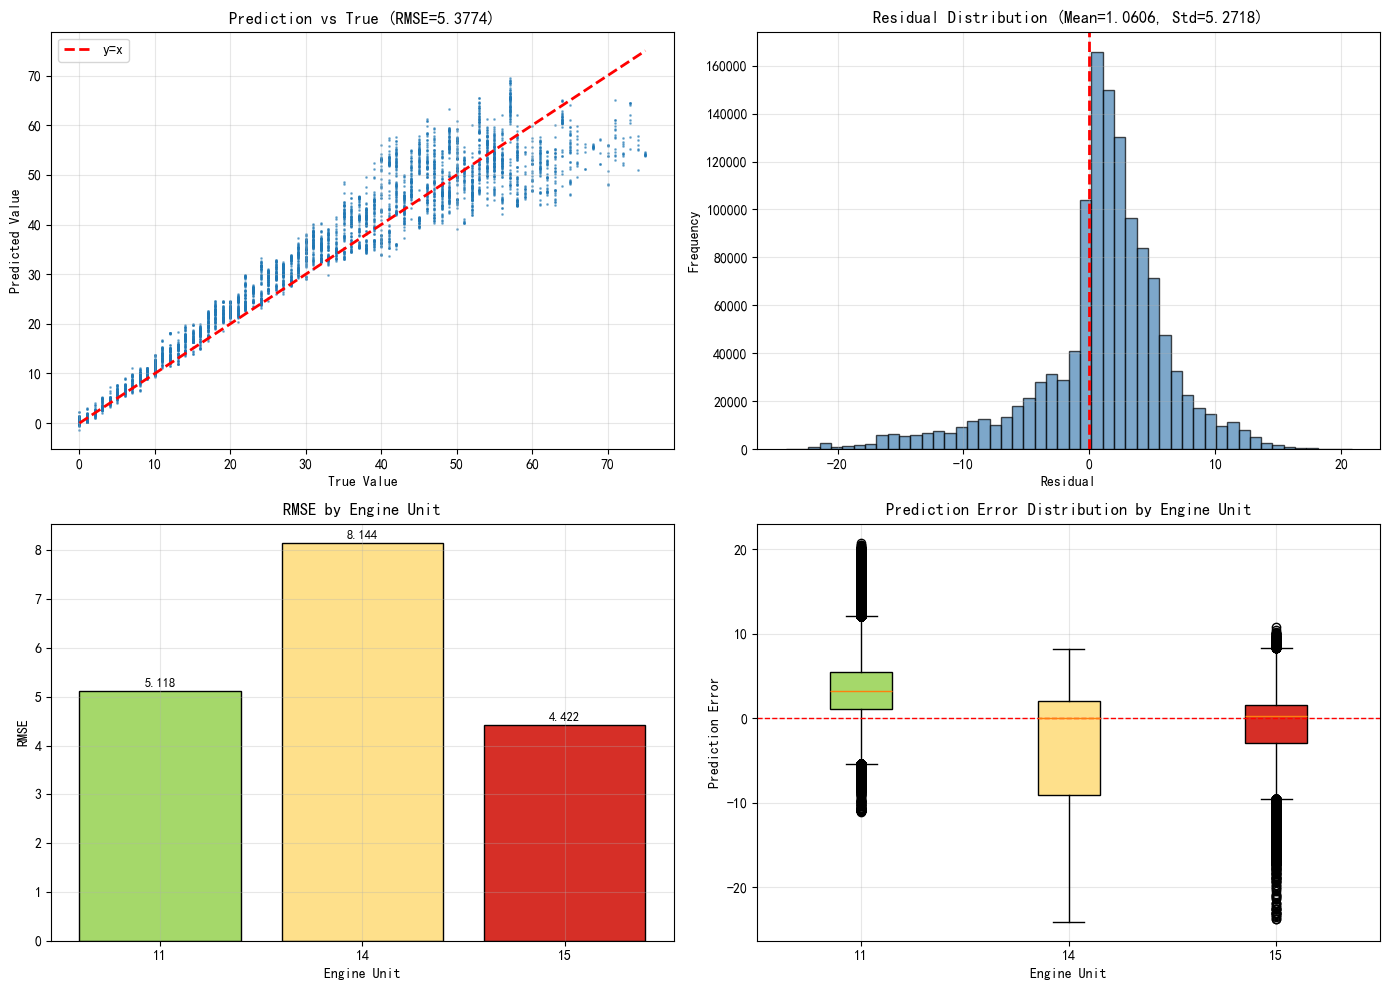


✅ 可视化图片已保存: cnn_test_results.png

📊 模型参数量: 109,121


In [2]:
# ==================== 测试评估 + 可视化（独立Cell） ====================
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import time

# 设置设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

# ==================== 1. 重新定义模型结构（必须与训练时一致） ====================
class CNNModel(nn.Module):
    def __init__(self, input_size=18, window_size=50):
        super(CNNModel, self).__init__()
        
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )
        
        self.conv2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )
        
        self.conv3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1))
        )
        
        self.conv4 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        
        self.fc1 = nn.Linear(128, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, 1)
        
        self._initialize_weights()
    
    def _initialize_weights(self):
        for name, param in self.named_parameters():
            if 'weight' in name and len(param.shape) >= 2:
                nn.init.kaiming_normal_(param, mode='fan_out', nonlinearity='relu')
            elif 'bias' in name:
                nn.init.zeros_(param)
    
    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x


# ==================== 2. 加载测试数据 ====================
# 注意：这里需要你的 X_test, Y_test, unit_test, window_size 变量
# 如果这些变量不存在，需要重新加载数据

try:
    # 假设这些变量已经存在
    test_dataset = NCMAPSSDataset(X_test, Y_test, unit_test, window_size=50)
    print(f"测试样本数: {len(test_dataset):,}")
except NameError:
    print("⚠️ 数据变量不存在，请先运行数据加载部分")
    # 重新加载数据
    import h5py
    file_path = "N-CMAPSS_DS02-006.h5"
    with h5py.File(file_path, 'r') as f:
        W_test = f['W_test'][:]
        Xs_test = f['X_s_test'][:]
        A_test = f['A_test'][:]
        Y_test = f['Y_test'][:]
    X_test = np.concatenate([W_test, Xs_test], axis=1)
    unit_test = A_test[:, 0].astype(int)
    
    # 归一化（需要训练集的X_min, X_max）
    # 如果X_min, X_max不存在，需要重新计算
    try:
        X_test = 2 * (X_test - X_min) / denom - 1
    except NameError:
        print("⚠️ 归一化参数不存在，请先运行数据加载部分")
        raise
    
    test_dataset = NCMAPSSDataset(X_test, Y_test, unit_test, window_size=50)
    print(f"测试样本数: {len(test_dataset):,}")

test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False,
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

# ==================== 3. 加载模型 ====================
model = CNNModel(input_size=18, window_size=50).to(device)

# 尝试加载模型，支持不同的文件名
model_files = ["best_cnn_model.pth", "best_cnn_model—.pth", "best_model.pth"]
loaded = False
for fname in model_files:
    try:
        model.load_state_dict(torch.load(fname, map_location=device))
        print(f"✅ 加载模型: {fname}")
        loaded = True
        break
    except FileNotFoundError:
        continue

if not loaded:
    print("❌ 未找到模型文件，请检查文件名")
    # 列出当前目录下的.pth文件
    import os
    pth_files = [f for f in os.listdir('.') if f.endswith('.pth')]
    print(f"当前目录下的.pth文件: {pth_files}")

model.eval()

# ==================== 4. 测试 ====================
print("\n开始测试...")
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in tqdm(test_loader, desc="Testing", ncols=100):
        X_batch = X_batch.to(device)
        Y_batch = Y_batch.to(device)
        outputs = model(X_batch)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(Y_batch.cpu().numpy())

all_preds = np.vstack(all_preds)
all_targets = np.vstack(all_targets)

# ==================== 5. 计算指标 ====================
mse = np.mean((all_preds - all_targets) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(all_preds - all_targets))

print("\n" + "="*60)
print("测试结果:")
print("="*60)
print(f"  MSE:  {mse:.4f}")
print(f"  RMSE: {rmse:.4f}")
print(f"  MAE:  {mae:.4f}")
print("="*60)

# ==================== 6. 按发动机评估 ====================
test_unit_labels = []
for idx in range(len(test_dataset)):
    start = test_dataset.valid_indices[idx]
    test_unit_labels.append(unit_test[start])
test_unit_labels = np.array(test_unit_labels)

unit_rmses = []
unit_names = []
for unit in np.unique(test_unit_labels):
    mask = test_unit_labels == unit
    unit_preds = all_preds[mask]
    unit_targets = all_targets[mask]
    unit_rmse = np.sqrt(np.mean((unit_preds - unit_targets) ** 2))
    unit_rmses.append(unit_rmse)
    unit_names.append(str(unit))

print("\n按发动机单元分别评估:")
print("-"*50)
for unit, rmse_val in zip(unit_names, unit_rmses):
    mask = test_unit_labels == int(unit)
    count = np.sum(mask)
    print(f"  Unit {unit:>2s}: RMSE = {rmse_val:.4f}, 样本数 = {count:,}")

# ==================== 7. 可视化 ====================
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 7.1 预测 vs 真实值散点图
ax1 = axes[0, 0]
sample_size = min(5000, len(all_preds))
indices = np.random.choice(len(all_preds), sample_size, replace=False)
ax1.scatter(all_targets[indices], all_preds[indices], alpha=0.5, s=1)
ax1.plot([all_targets.min(), all_targets.max()], 
         [all_targets.min(), all_targets.max()], 
         'r--', linewidth=2, label='y=x')
ax1.set_xlabel('True Value')
ax1.set_ylabel('Predicted Value')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_title(f'Prediction vs True (RMSE={rmse:.4f})')

# 7.2 残差分布
ax2 = axes[0, 1]
residuals = all_preds.flatten() - all_targets.flatten()
ax2.hist(residuals, bins=50, alpha=0.7, edgecolor='black', color='steelblue')
ax2.axvline(x=0, color='r', linestyle='--', linewidth=2)
ax2.set_xlabel('Residual')
ax2.set_ylabel('Frequency')
ax2.set_title(f'Residual Distribution (Mean={np.mean(residuals):.4f}, Std={np.std(residuals):.4f})')
ax2.grid(True, alpha=0.3)

# 7.3 按发动机RMSE柱状图
ax3 = axes[1, 0]
colors = plt.cm.RdYlGn_r(np.linspace(0.3, 0.9, len(unit_names)))
bars = ax3.bar(unit_names, unit_rmses, color=colors, edgecolor='black')
ax3.set_xlabel('Engine Unit')
ax3.set_ylabel('RMSE')
ax3.set_title('RMSE by Engine Unit')
ax3.grid(True, alpha=0.3)

# 在柱子上显示数值
for bar, val in zip(bars, unit_rmses):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)

# 7.4 箱线图：各发动机预测误差分布
ax4 = axes[1, 1]
errors_by_unit = []
unit_labels_for_box = []
for unit in np.unique(test_unit_labels):
    mask = test_unit_labels == unit
    unit_errors = (all_preds[mask] - all_targets[mask]).flatten()
    errors_by_unit.append(unit_errors)
    unit_labels_for_box.append(str(unit))

bp = ax4.boxplot(errors_by_unit, labels=unit_labels_for_box, patch_artist=True)
for patch, color in zip(bp['boxes'], plt.cm.RdYlGn_r(np.linspace(0.3, 0.9, len(unit_labels_for_box)))):
    patch.set_facecolor(color)
ax4.axhline(y=0, color='r', linestyle='--', linewidth=1)
ax4.set_xlabel('Engine Unit')
ax4.set_ylabel('Prediction Error')
ax4.set_title('Prediction Error Distribution by Engine Unit')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('cnn_test_results.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ 可视化图片已保存: cnn_test_results.png")

# ==================== 8. 模型参数量 ====================
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n📊 模型参数量: {count_parameters(model):,}")